In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Library berhasil di-import!")

Library berhasil di-import!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving 9b7d708f-6afe-4334-9ab9-ab84ff82a21b.xlsx to 9b7d708f-6afe-4334-9ab9-ab84ff82a21b.xlsx


In [ ]:
import os

print(os.listdir())

In [ ]:
file_name = list(uploaded.keys())[0]

excel_file = pd.ExcelFile(file_name)

print(excel_file.sheet_names)

['Pertanyaan', 'PivoteTable', 'Dynamic_Array', 'All_Transactions', 'Product_Master (2)', 'Input Data Baru', 'Product_Master', 'Sales_Store1 (2)', 'Sales_Store1', 'Sales_Store2 (2)', 'Sales_Store2', 'Sales_Store3 (2)', 'Sales_Store3', 'Customer_Master (2)', 'Customer_Master', 'Store_Master (2)', 'Store_Master']


In [ ]:
df = pd.read_excel(
    file_name,
    sheet_name="All_Transactions"
)

print("Data berhasil dibaca!")

Data berhasil dibaca!


In [ ]:
df.head()

,StoreID,Date,Years,CustomerID,ProductID,ProductName,Quantity,SalesAmount,Cost,City,Region,Customer_Master.CustomerName,Customer_Master.Age,Customer_Master.Gender,Product_Master.Category,Store_Master.StoreName
0,S001,2025-09-07,2025,C5710,P004,Headphone Z,5,19355,2500,Jakarta,Jabodetabek,Aslijan Wasita,53,Female,Accessories,Jakarta Center
1,S001,2024-10-05,2024,C5710,P004,Headphone Z,5,6790,2500,Jakarta,Jabodetabek,Aslijan Wasita,53,Female,Accessories,Jakarta Center
2,S002,2025-04-30,2025,C1,P003,Tablet Air,4,22804,12000,Bandung,Jawa Barat,Ami Nainggolan,30,Male,Electronics,Bandung Point
3,S002,2024-09-24,2024,C1,P003,Tablet Air,4,25408,12000,Bandung,Jawa Barat,Ami Nainggolan,30,Male,Electronics,Bandung Point
4,S002,2025-02-03,2025,C2,P003,Tablet Air,3,11829,9000,Bandung,Jawa Barat,Endah Laksmiwati,18,Male,Electronics,Bandung Point


In [ ]:
df.shape

(14999, 16)

In [ ]:
df.columns

Index(['StoreID', 'Date', 'Years', 'CustomerID', 'ProductID', 'ProductName',
       'Quantity', 'SalesAmount', 'Cost', 'City', 'Region',
       'Customer_Master.CustomerName', 'Customer_Master.Age',
       'Customer_Master.Gender', 'Product_Master.Category',
       'Store_Master.StoreName'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 16 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   StoreID                       14999 non-null  object        
 1   Date                          14999 non-null  datetime64[ns]
 2   Years                         14999 non-null  int64         
 3   CustomerID                    14999 non-null  object        
 4   ProductID                     14999 non-null  object        
 5   ProductName                   14999 non-null  object        
 6   Quantity                      14999 non-null  int64         
 7   SalesAmount                   14999 non-null  int64         
 8   Cost                          14999 non-null  int64         
 9   City                          14999 non-null  object        
 10  Region                        14999 non-null  object        
 11  Customer_Master.CustomerName

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['CustomerID'].nunique()

9068

In [ ]:
print("Tanggal transaksi paling awal :", df['Date'].min())
print("Tanggal transaksi paling akhir:", df['Date'].max())

Tanggal transaksi paling awal : 2024-02-28 00:00:00
Tanggal transaksi paling akhir: 2025-09-07 00:00:00


In [ ]:
df[['Quantity', 'SalesAmount', 'Cost', 'Customer_Master.Age']].describe()

,Quantity,SalesAmount,Cost,Customer_Master.Age
count,14999.000000,14999.000000,14999.000000,14999.000000
mean,2.978665,16819.842389,8612.427495,41.286352
std,1.407341,12167.277846,9133.940374,13.906742
min,-3.000000,0.000000,0.000000,18.000000
25%,2.000000,7390.000000,1000.000000,29.000000
50%,3.000000,13833.000000,6000.000000,41.000000
75%,4.000000,23419.000000,14000.000000,53.000000
max,5.000000,59970.000000,35000.000000,65.000000


In [ ]:
profiling = pd.DataFrame({
    'Column': df.columns,
    'Data Type': df.dtypes.astype(str).values,
    'Missing Value': df.isnull().sum().values,
    'Unique Value': df.nunique().values
})

profiling

,Column,Data Type,Missing Value,Unique Value
0,StoreID,object,0,3
1,Date,datetime64[ns],0,367
2,Years,int64,0,2
3,CustomerID,object,0,9068
4,ProductID,object,0,5
5,ProductName,object,0,5
6,Quantity,int64,0,8
7,SalesAmount,int64,0,11217
8,Cost,int64,0,24
9,City,object,0,3


In [ ]:
df['Profit'] = df['SalesAmount'] - df['Cost']

df[['SalesAmount', 'Cost', 'Profit']].head()

,SalesAmount,Cost,Profit
0,19355,2500,16855
1,6790,2500,4290
2,22804,12000,10804
3,25408,12000,13408
4,11829,9000,2829


In [ ]:
df[['SalesAmount', 'Cost', 'Profit']].head(10)

,SalesAmount,Cost,Profit
0,19355,2500,16855
1,6790,2500,4290
2,22804,12000,10804
3,25408,12000,13408
4,11829,9000,2829
5,3868,400,3468
6,4660,200,4460
7,3697,3000,697
8,15771,12000,3771
9,32830,15000,17830


In [ ]:
print("Jumlah transaksi dengan Profit negatif:",
      (df['Profit'] < 0).sum())

Jumlah transaksi dengan Profit negatif: 1


In [ ]:
df['Profit'].describe()

,Profit
count,14999.000000
mean,8207.414894
std,5817.419938
min,-35000.000000
25%,3507.500000
50%,6780.000000
75%,11910.000000
max,24995.000000


In [ ]:
print("Jumlah baris:", len(df))
print("Jumlah kolom:", len(df.columns))

print("\nMissing value:")
print(df.isnull().sum().sum())

print("\nDuplicate:")
print(df.duplicated().sum())

print("\nQuantity negatif:")
print((df['Quantity'] < 0).sum())

print("\nSalesAmount <= 0:")
print((df['SalesAmount'] <= 0).sum())

Jumlah baris: 14999
Jumlah kolom: 17

Missing value:
0

Duplicate:
0

Quantity negatif:
3

SalesAmount <= 0:
1


In [ ]:
df_clean = df.copy()

In [ ]:
df_clean = df_clean[
    (df_clean['Quantity'] > 0) &
    (df_clean['SalesAmount'] > 0)
].copy()

In [ ]:
print("Jumlah data awal :", len(df))
print("Jumlah data bersih:", len(df_clean))
print("Data yang dikeluarkan:", len(df) - len(df_clean))

Jumlah data awal : 14999
Jumlah data bersih: 14995
Data yang dikeluarkan: 4


In [ ]:
df_clean[
    ['Date',
     'CustomerID',
     'ProductName',
     'Quantity',
     'SalesAmount',
     'Cost',
     'Profit']
].head(10)

,Date,CustomerID,ProductName,Quantity,SalesAmount,Cost,Profit
0,2025-09-07,C5710,Headphone Z,5,19355,2500,16855
1,2024-10-05,C5710,Headphone Z,5,6790,2500,4290
2,2025-04-30,C1,Tablet Air,4,22804,12000,10804
3,2024-09-24,C1,Tablet Air,4,25408,12000,13408
4,2025-02-03,C2,Tablet Air,3,11829,9000,2829
5,2025-09-07,C4644,Charger Fast,2,3868,400,3468
6,2025-09-07,C3461,Charger Fast,1,4660,200,4460
7,2025-02-18,C3461,Tablet Air,1,3697,3000,697
8,2025-08-20,C3,Smartphone X,3,15771,12000,3771
9,2024-11-08,C3,Tablet Air,5,32830,15000,17830


Exploratory Data Analysis (EDA)

DISTRIBUSI SALES

Sebaran nilai transaksi customer seperti apa ??

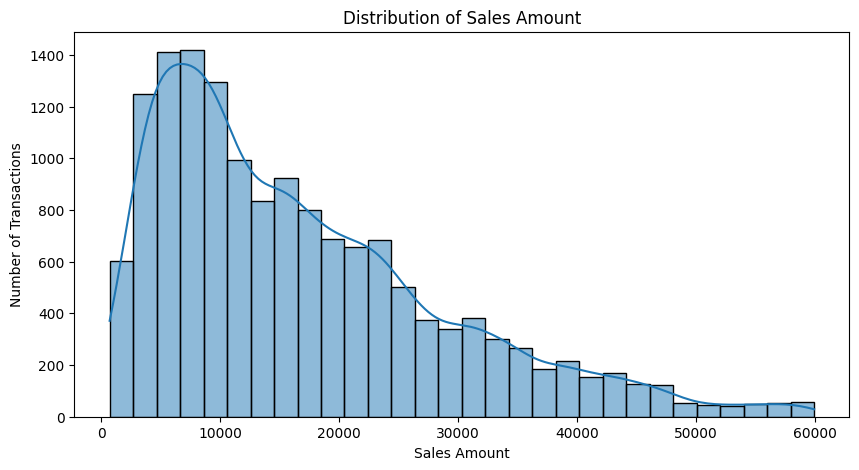

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x='SalesAmount',
    bins=30,
    kde=True
)

plt.title('Distribution of Sales Amount')
plt.xlabel('Sales Amount')
plt.ylabel('Number of Transactions')

plt.show()

**Tren Sales Bulanan**



Bagaimana perkembangan penjualan dari waktu ke waktu?

In [ ]:
df_clean['Month'] = df_clean['Date'].dt.to_period('M')

In [ ]:
monthly_sales = (
    df_clean
    .groupby('Month')['SalesAmount']
    .sum()
    .reset_index()
)

monthly_sales['Month'] = monthly_sales['Month'].astype(str)

monthly_sales.head()

,Month,SalesAmount
0,2024-02,23795
1,2024-09,15904274
2,2024-10,19772054
3,2024-11,20285172
4,2024-12,22026257


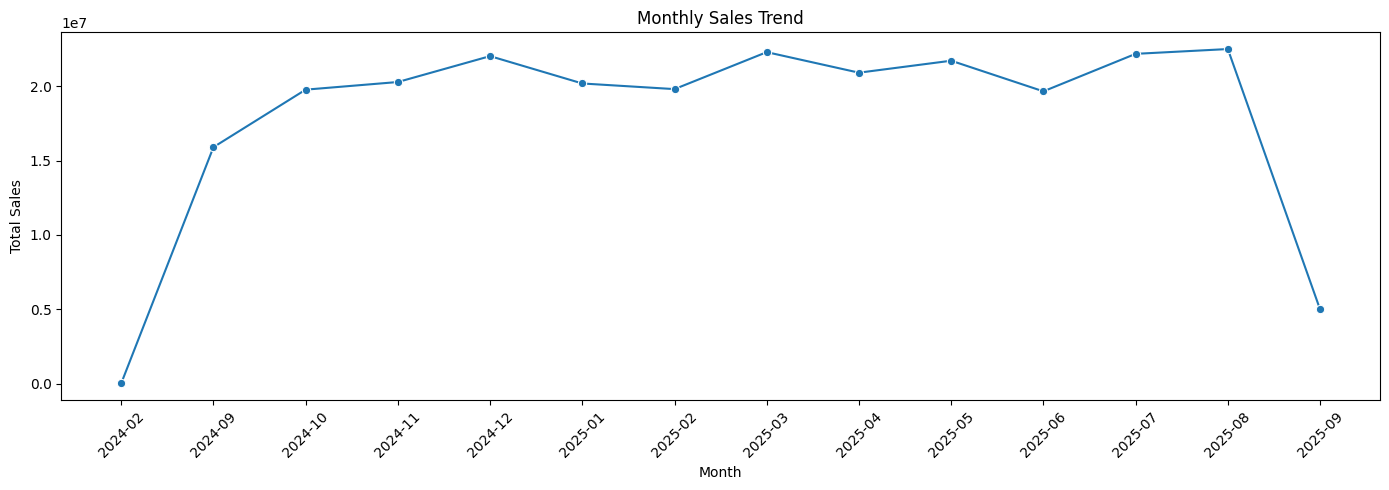

In [ ]:
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_sales,
    x='Month',
    y='SalesAmount',
    marker='o'
)

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Sales Berdasarkan Produk**



Produk apa yang menghasilkan sales terbesar?

In [ ]:
product_sales = (
    df_clean
    .groupby('ProductName')['SalesAmount']
    .sum()
    .sort_values(ascending=False)
)

display(product_sales)

,SalesAmount
ProductName,
Laptop Pro,84452308
Smartphone X,60080890
Tablet Air,50667159
Headphone Z,30066205
Charger Fast,27003640


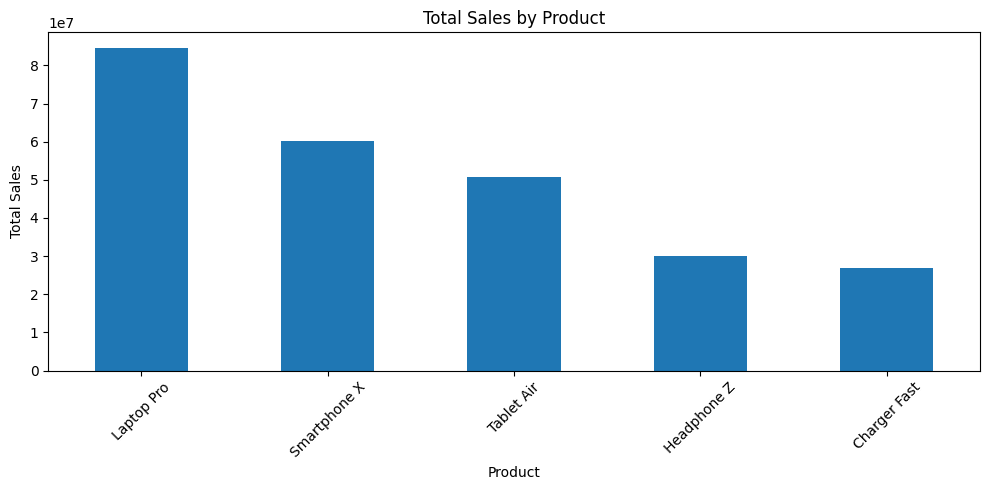

In [ ]:
plt.figure(figsize=(10, 5))

product_sales.plot(kind='bar')

plt.title('Total Sales by Product')
plt.xlabel('Product')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**SALES Berdasarkan Region**

In [ ]:
region_sales = (
    df_clean
    .groupby('Region')['SalesAmount']
    .sum()
    .sort_values(ascending=False)
)

display(region_sales)

,SalesAmount
Region,
Jawa Barat,84604679
Jabodetabek,83999445
Jawa Timur,83666078


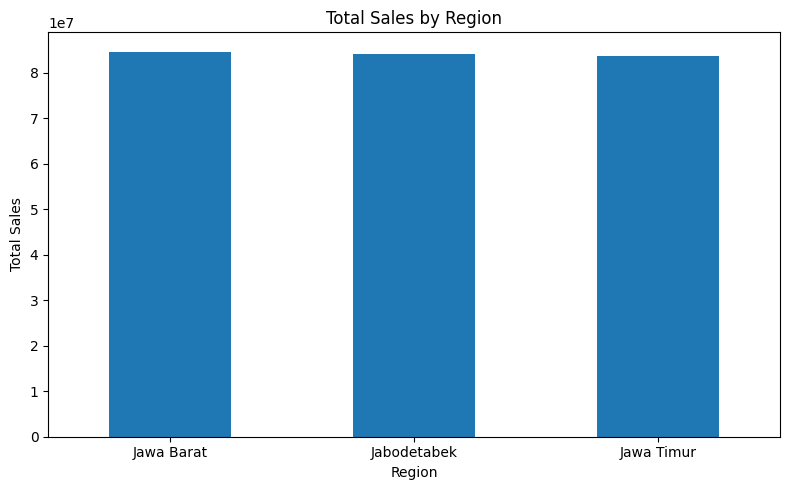

In [ ]:
plt.figure(figsize=(8, 5))

region_sales.plot(kind='bar')

plt.title('Total Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales')

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

**Sales Berdasarkan Store**

In [ ]:
store_sales = (
    df_clean
    .groupby('Store_Master.StoreName')['SalesAmount']
    .sum()
    .sort_values(ascending=False)
)

display(store_sales)

,SalesAmount
Store_Master.StoreName,
Bandung Point,84604679
Jakarta Center,83999445
Surabaya Plaza,83666078


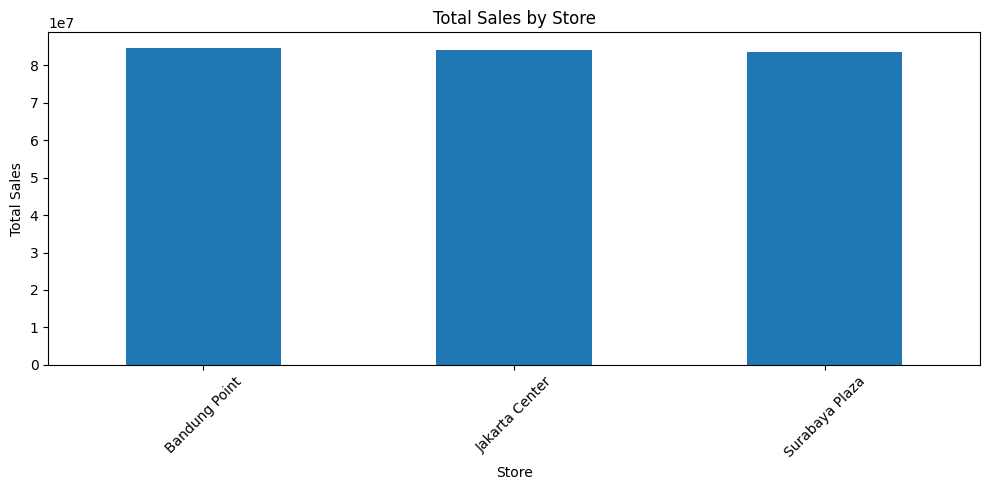

In [ ]:
plt.figure(figsize=(10, 5))

store_sales.plot(kind='bar')

plt.title('Total Sales by Store')
plt.xlabel('Store')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Quantity Produk**

In [ ]:
quantity_product = (
    df_clean
    .groupby('ProductName')['Quantity']
    .sum()
    .sort_values(ascending=False)
)

display(quantity_product)

,Quantity
ProductName,
Headphone Z,9236
Charger Fast,9078
Smartphone X,8928
Tablet Air,8764
Laptop Pro,8672


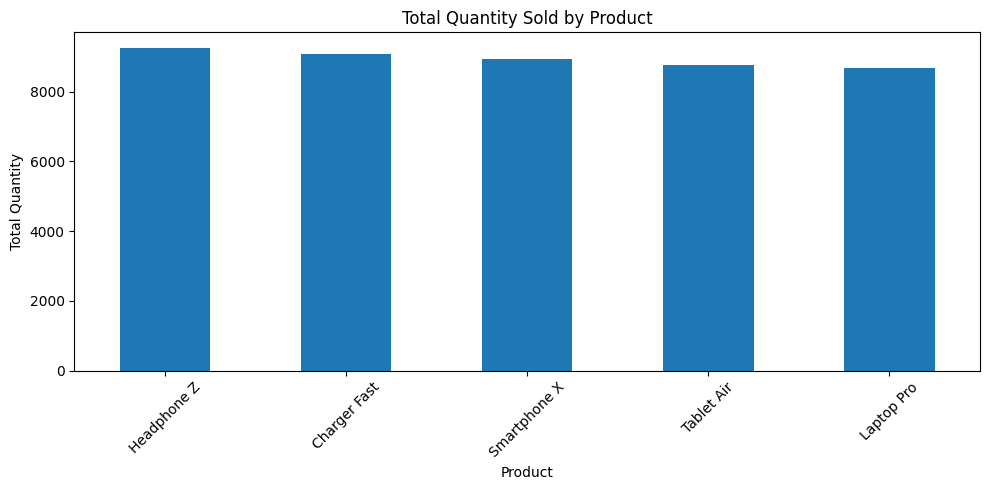

In [ ]:
plt.figure(figsize=(10, 5))

quantity_product.plot(kind='bar')

plt.title('Total Quantity Sold by Product')
plt.xlabel('Product')
plt.ylabel('Total Quantity')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Profit Berdasarkan Produk**

In [ ]:
product_profit = (
    df_clean
    .groupby('ProductName')['Profit']
    .sum()
    .sort_values(ascending=False)
)

display(product_profit)

,Profit
ProductName,
Headphone Z,25448205
Charger Fast,25188040
Tablet Air,24375159
Smartphone X,24368890
Laptop Pro,23748308


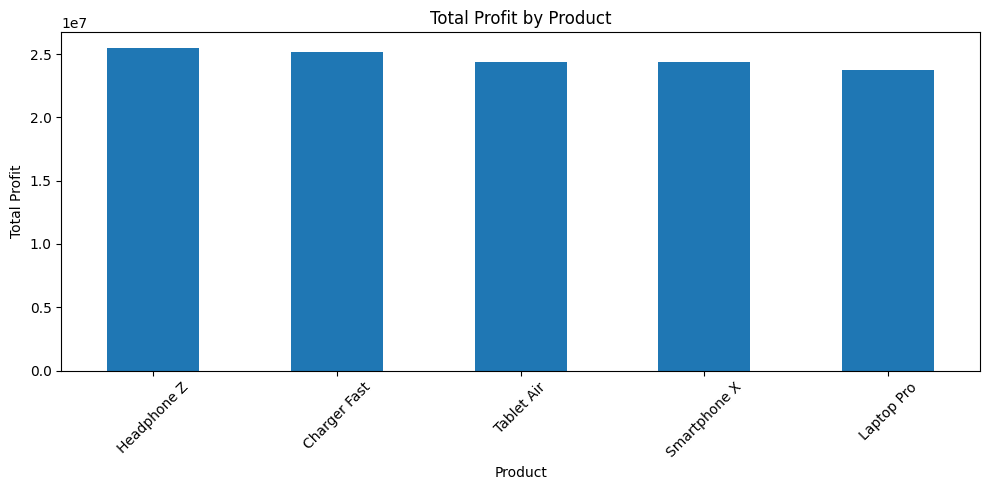

In [ ]:
plt.figure(figsize=(10, 5))

product_profit.plot(kind='bar')

plt.title('Total Profit by Product')
plt.xlabel('Product')
plt.ylabel('Total Profit')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Sales Berdasarkan Category**

In [ ]:
category_sales = (
    df_clean
    .groupby('Product_Master.Category')['SalesAmount']
    .sum()
    .sort_values(ascending=False)
)

display(category_sales)

,SalesAmount
Product_Master.Category,
Electronics,195200357
Accessories,57069845


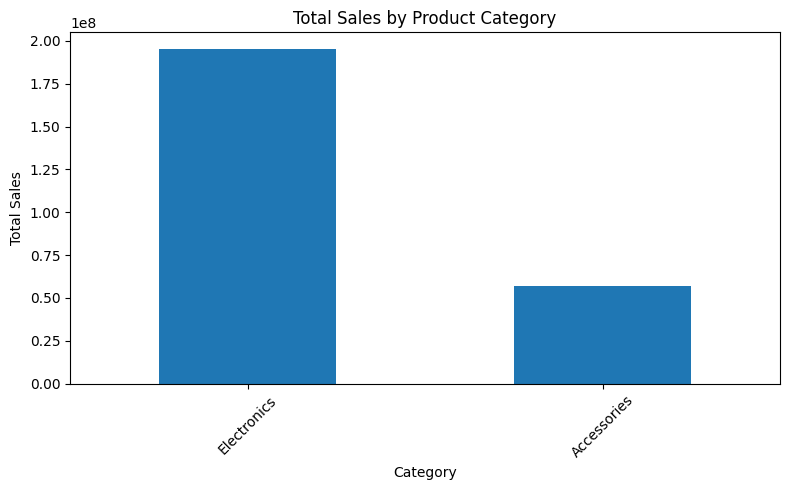

In [ ]:
plt.figure(figsize=(8, 5))

category_sales.plot(kind='bar')

plt.title('Total Sales by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Customer berdasarkan Gender**

In [ ]:
gender_count = (
    df_clean['Customer_Master.Gender']
    .value_counts()
)

display(gender_count)

,count
Customer_Master.Gender,
Male,7558
Female,7437


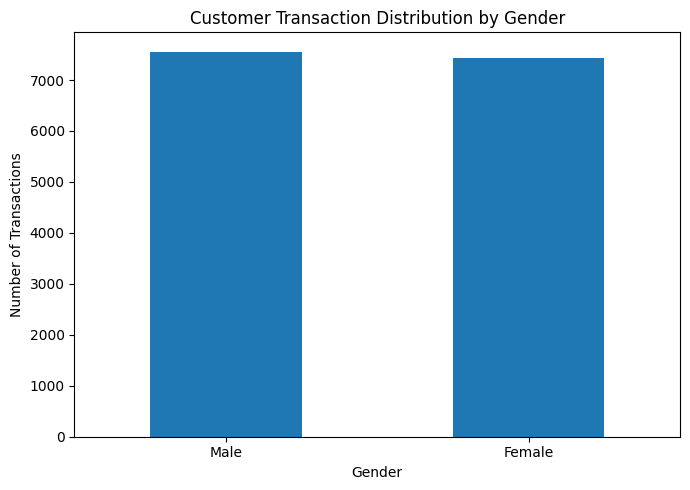

In [ ]:
plt.figure(figsize=(7, 5))

gender_count.plot(kind='bar')

plt.title('Customer Transaction Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Transactions')

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

**Distribusi Usia Customer**

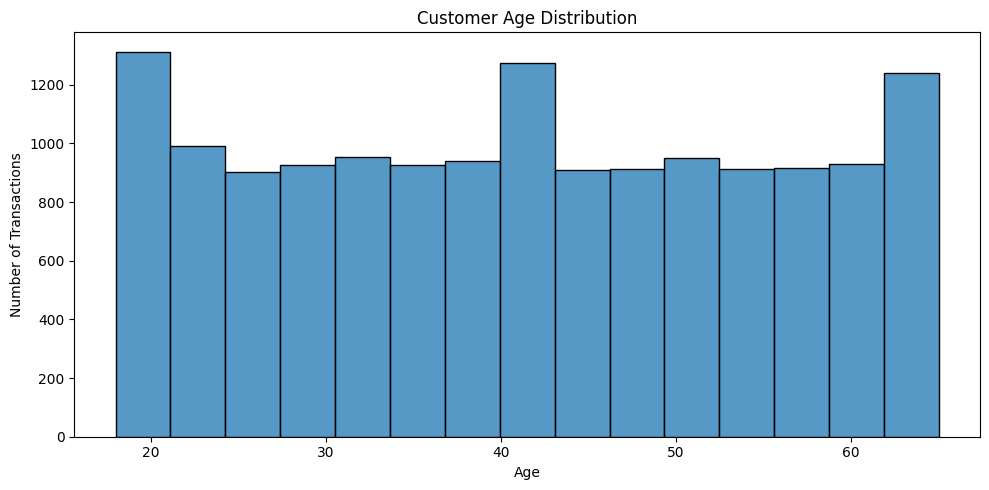

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x='Customer_Master.Age',
    bins=15
)

plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Transactions')

plt.tight_layout()
plt.show()

**Sales vs Profit**

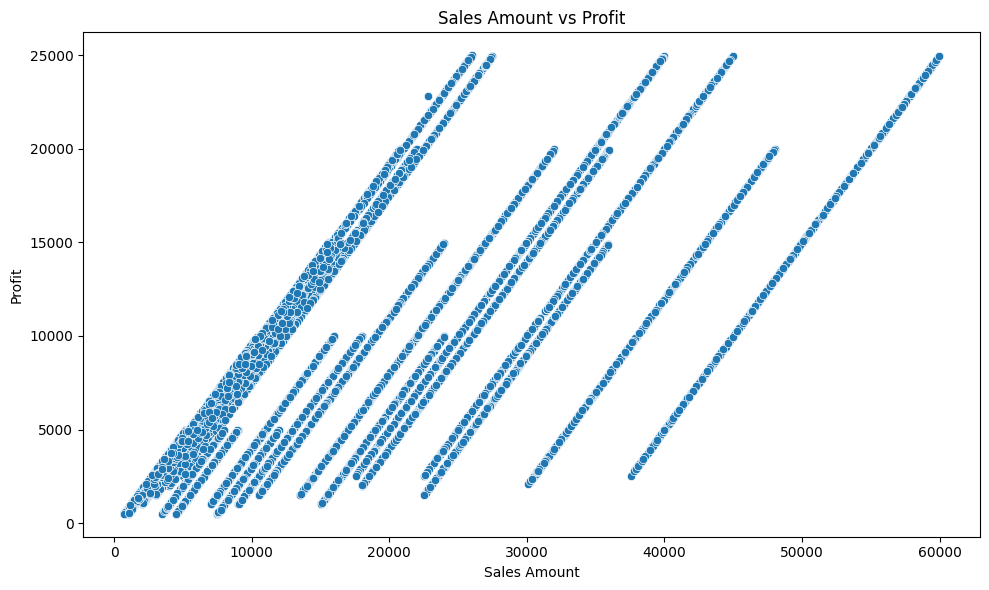

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x='SalesAmount',
    y='Profit'
)

plt.title('Sales Amount vs Profit')
plt.xlabel('Sales Amount')
plt.ylabel('Profit')

plt.tight_layout()
plt.show()

**Top 10 Customer**

In [ ]:
top_customers = (
    df_clean
    .groupby('CustomerID')['SalesAmount']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_customers)

,SalesAmount
CustomerID,
C3523,115090
C2217,103009
C9390,101373
C12211,99755
C4518,95000
C935,94800
C9232,94636
C10020,94333
C9481,94217


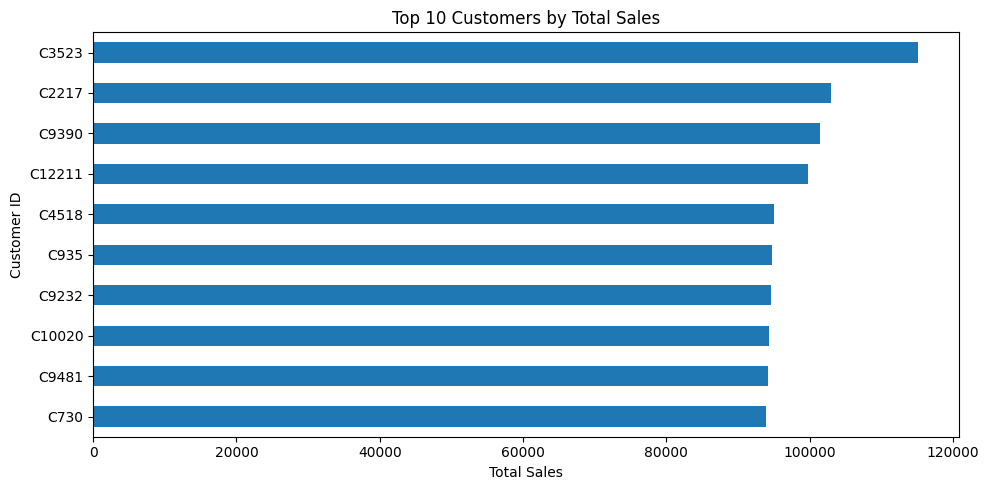

In [ ]:
plt.figure(figsize=(10, 5))

top_customers.sort_values().plot(
    kind='barh'
)

plt.title('Top 10 Customers by Total Sales')
plt.xlabel('Total Sales')
plt.ylabel('Customer ID')

plt.tight_layout()
plt.show()

**RFM ANALYSIS
4.1 Apa itu RFM?**

RFM digunakan untuk memahami perilaku customer berdasarkan 3 indikator:

** R — Recency**

Dari tanggal berapa Recency dihitung?

In [ ]:
analysis_date = df_clean['Date'].max() + pd.Timedelta(days=1)

print("Tanggal transaksi terakhir:", df_clean['Date'].max())
print("Analysis date:", analysis_date)

Tanggal transaksi terakhir: 2025-09-07 00:00:00
Analysis date: 2025-09-08 00:00:00


**Tabel Menghitung RFM**

In [ ]:
rfm = (
    df_clean
    .groupby('CustomerID')
    .agg(
        Recency=('Date', lambda x: (analysis_date - x.max()).days),
        Frequency=('CustomerID', 'count'),
        Monetary=('SalesAmount', 'sum')
    )
    .reset_index()
)

rfm.head(10)

,CustomerID,Recency,Frequency,Monetary
0,C1,131,2,48212
1,C10,78,1,18280
2,C100,202,2,15074
3,C1000,308,2,22198
4,C10000,56,2,25268
5,C10001,65,2,12474
6,C10002,129,2,22540
7,C10003,211,1,8206
8,C10004,70,1,12662
9,C10005,174,1,30668


In [ ]:
print("Jumlah customer dalam RFM:", rfm['CustomerID'].nunique())

Jumlah customer dalam RFM: 9068


In [ ]:
rfm[['Recency', 'Frequency', 'Monetary']].describe()

,Recency,Frequency,Monetary
count,9068.000000,9068.000000,9068.000000
mean,142.878584,1.653617,27819.828187
std,97.797873,0.475843,17560.026618
min,1.000000,1.000000,710.000000
25%,59.000000,1.000000,14069.500000
50%,129.000000,2.000000,24736.500000
75%,215.000000,2.000000,38497.000000
max,366.000000,2.000000,115090.000000


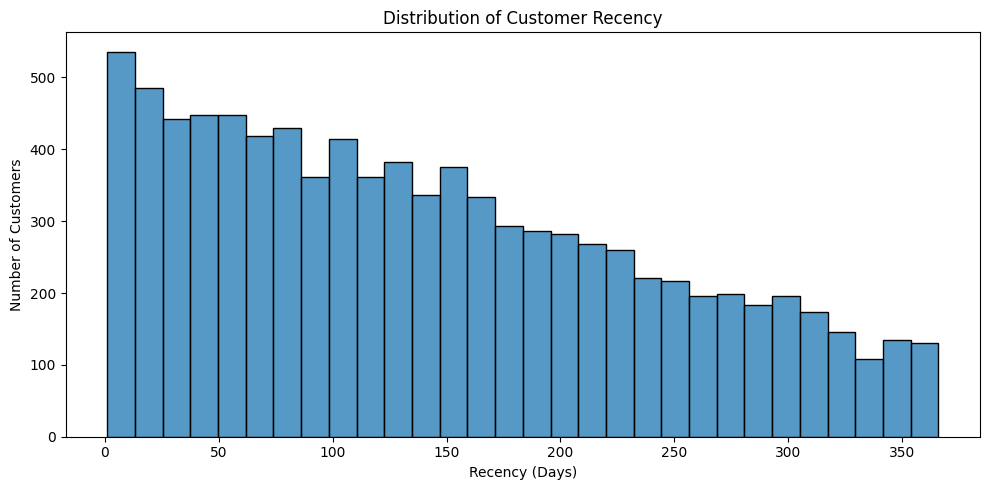

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=rfm,
    x='Recency',
    bins=30
)

plt.title('Distribution of Customer Recency')
plt.xlabel('Recency (Days)')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

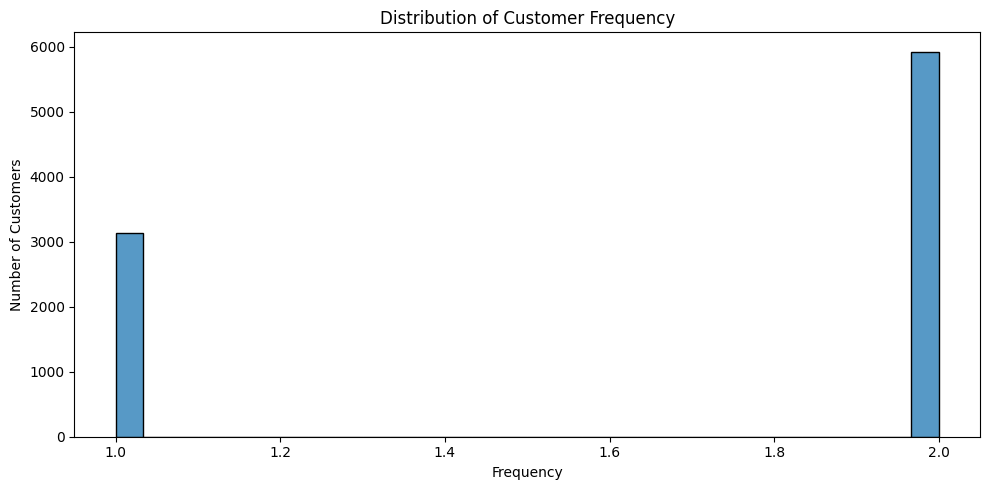

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=rfm,
    x='Frequency',
    bins=30
)

plt.title('Distribution of Customer Frequency')
plt.xlabel('Frequency')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

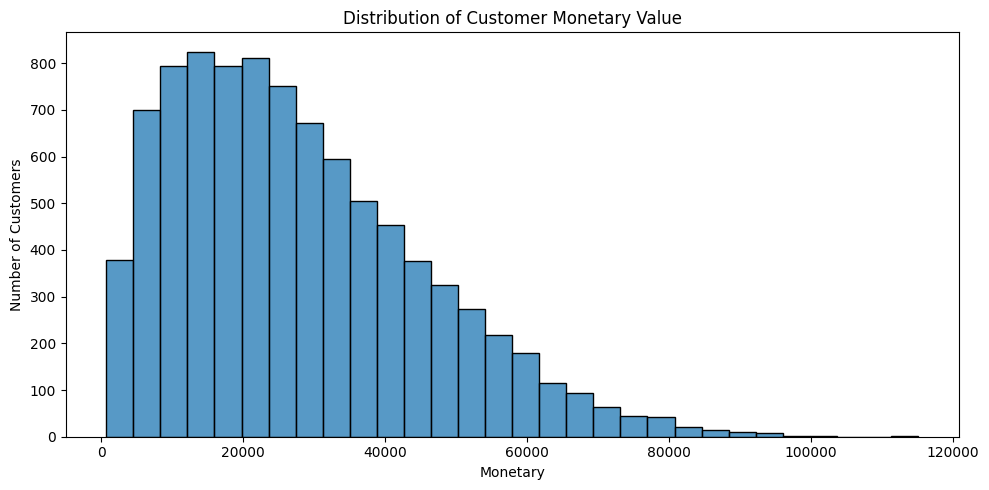

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=rfm,
    x='Monetary',
    bins=30
)

plt.title('Distribution of Customer Monetary Value')
plt.xlabel('Monetary')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

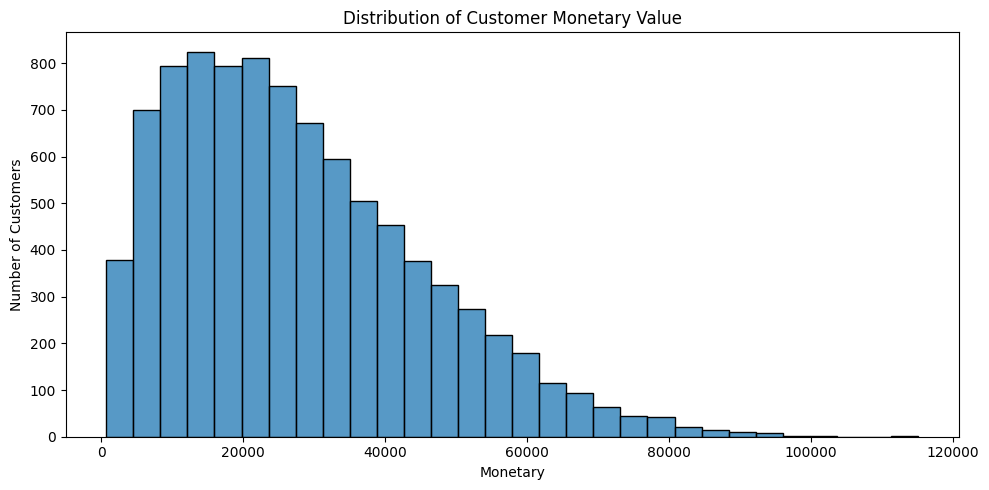

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=rfm,
    x='Monetary',
    bins=30
)

plt.title('Distribution of Customer Monetary Value')
plt.xlabel('Monetary')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

In [ ]:
### R score
rfm['R_Score'] = pd.qcut(
    rfm['Recency'].rank(method='first'),
    q=5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

In [ ]:
### F score
rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

In [ ]:
##M Score
rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

In [ ]:
### Lihat hasil scoring
rfm[
    [
        'CustomerID',
        'Recency',
        'Frequency',
        'Monetary',
        'R_Score',
        'F_Score',
        'M_Score'
    ]
].head(20)

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,C1,131,2,48212,3,2,5
1,C10,78,1,18280,4,1,2
2,C100,202,2,15074,2,2,2
3,C1000,308,2,22198,1,2,3
4,C10000,56,2,25268,4,2,3
5,C10001,65,2,12474,4,2,2
6,C10002,129,2,22540,3,2,3
7,C10003,211,1,8206,2,1,1
8,C10004,70,1,12662,4,1,2
9,C10005,174,1,30668,2,1,4


In [ ]:
##Membuat RFM Score
rfm['RFM_Score'] = (
    rfm['R_Score'].astype(str) +
    rfm['F_Score'].astype(str) +
    rfm['M_Score'].astype(str)
)

rfm.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,C1,131,2,48212,3,2,5,325
1,C10,78,1,18280,4,1,2,412
2,C100,202,2,15074,2,2,2,222
3,C1000,308,2,22198,1,2,3,123
4,C10000,56,2,25268,4,2,3,423


In [ ]:
## Membuat Segmentasi Customer
def rfm_segment(row):

    r = row['R_Score']
    f = row['F_Score']
    m = row['M_Score']

    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'

    elif r >= 3 and f >= 4 and m >= 3:
        return 'Loyal Customers'

    elif r >= 4 and f <= 3 and m >= 3:
        return 'Potential Loyalists'

    elif r <= 2 and f >= 3 and m >= 3:
        return 'At Risk'

    elif r <= 2 and f <= 2:
        return 'Lost Customers'

    else:
        return 'Need Attention'

In [ ]:
rfm['Segment'] = rfm.apply(
    rfm_segment,
    axis=1
)

In [ ]:
##Lihat Hasil Segmentasi
rfm[
    [
        'CustomerID',
        'RFM_Score',
        'Segment'
    ]
].head(20)

,CustomerID,RFM_Score,Segment
0,C1,325,Need Attention
1,C10,412,Need Attention
2,C100,222,Lost Customers
3,C1000,123,Lost Customers
4,C10000,423,Potential Loyalists
5,C10001,422,Need Attention
6,C10002,323,Need Attention
7,C10003,211,Lost Customers
8,C10004,412,Need Attention
9,C10005,214,Lost Customers


In [ ]:
### menghitung jumlah Cudstomeer  per  segment
segment_count = (
    rfm['Segment']
    .value_counts()
)

display(segment_count)

,count
Segment,
Need Attention,2979
Lost Customers,1901
At Risk,1298
Potential Loyalists,1059
Loyal Customers,940
Champions,891


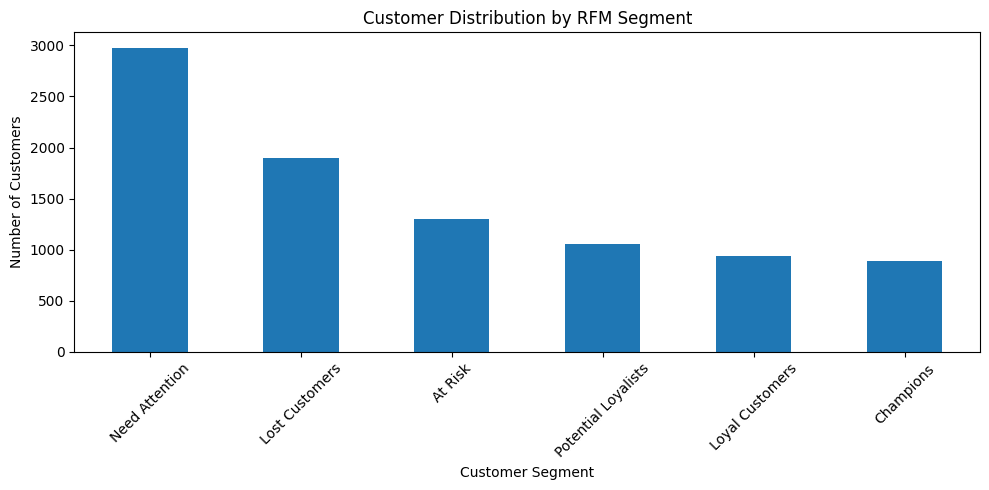

In [ ]:
###Visualisasi Segmentasi RFM
plt.figure(figsize=(10, 5))

segment_count.plot(kind='bar')

plt.title('Customer Distribution by RFM Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Total Monetary per Segment**
 Sekarang kita ingin tahu
Segment mana yang memberikan total revenue paling besar?

In [ ]:
segment_monetary = (
    rfm
    .groupby('Segment')['Monetary']
    .sum()
    .sort_values(ascending=False)
)

display(segment_monetary)

,Monetary
Segment,
At Risk,52489042
Need Attention,50644688
Champions,42096302
Potential Loyalists,40075678
Lost Customers,34730965
Loyal Customers,32233527


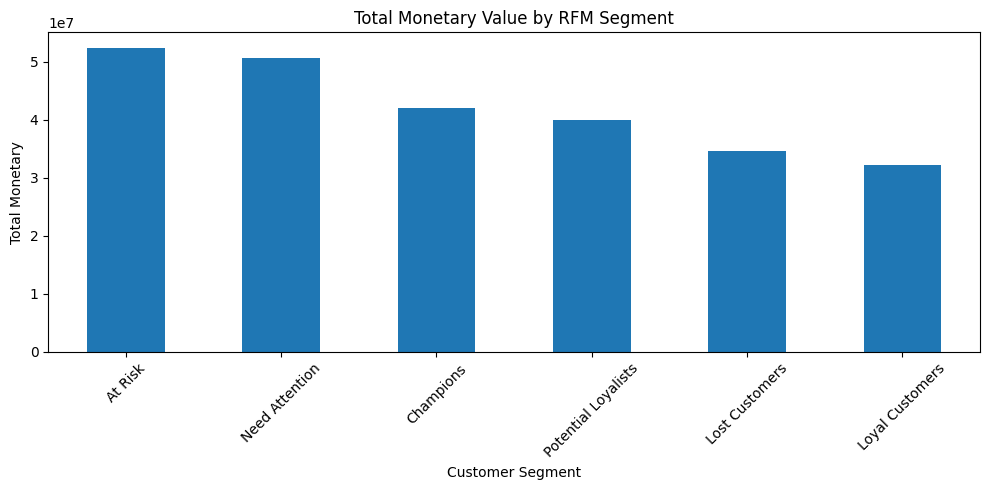

In [ ]:
plt.figure(figsize=(10, 5))

segment_monetary.plot(kind='bar')

plt.title('Total Monetary Value by RFM Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Monetary')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Rata-rata RFM per Segment**

Ini sangat bagus untuk memahami karakter setiap segment.

In [ ]:
rfm_summary = (
    rfm
    .groupby('Segment')
    [['Recency', 'Frequency', 'Monetary']]
    .mean()
    .sort_values('Monetary', ascending=False)
)

display(rfm_summary)

,Recency,Frequency,Monetary
Segment,,,
Champions,46.572391,2.000000,47246.130191
At Risk,227.707242,2.000000,40438.399076
Potential Loyalists,48.355996,1.755430,37842.944287
Loyal Customers,95.861702,2.000000,34290.986170
Lost Customers,260.931089,1.072067,18269.839558
Need Attention,107.826116,1.624706,17000.566633


**CUSTOMER LIFETIME VALUE**

In [ ]:
customer_value = (
    df_clean
    .groupby('CustomerID')
    .agg(
        Total_Revenue=('SalesAmount', 'sum'),
        Total_Cost=('Cost', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Quantity=('Quantity', 'sum'),
        Transaction_Count=('CustomerID', 'count'),
        First_Purchase=('Date', 'min'),
        Last_Purchase=('Date', 'max')
    )
    .reset_index()
)

customer_value.head()

,CustomerID,Total_Revenue,Total_Cost,Total_Profit,Total_Quantity,Transaction_Count,First_Purchase,Last_Purchase
0,C1,48212,24000,24212,8,2,2024-09-24,2025-04-30
1,C10,18280,800,17480,4,1,2025-06-22,2025-06-22
2,C100,15074,4000,11074,3,2,2025-01-10,2025-02-18
3,C1000,22198,13000,9198,3,2,2024-09-23,2024-11-04
4,C10000,25268,12200,13068,4,2,2025-06-26,2025-07-14


In [ ]:
###Customer Lifemetime
customer_value['Customer_Lifetime_Days'] = (
    customer_value['Last_Purchase'] -
    customer_value['First_Purchase']
).dt.days

In [ ]:
customer_value[
    [
        'CustomerID',
        'First_Purchase',
        'Last_Purchase',
        'Customer_Lifetime_Days'
    ]
].head(10)

,CustomerID,First_Purchase,Last_Purchase,Customer_Lifetime_Days
0,C1,2024-09-24,2025-04-30,218
1,C10,2025-06-22,2025-06-22,0
2,C100,2025-01-10,2025-02-18,39
3,C1000,2024-09-23,2024-11-04,42
4,C10000,2025-06-26,2025-07-14,18
5,C10001,2025-04-10,2025-07-05,86
6,C10002,2024-12-07,2025-05-02,146
7,C10003,2025-02-09,2025-02-09,0
8,C10004,2025-06-30,2025-06-30,0
9,C10005,2025-03-18,2025-03-18,0


In [ ]:
###Average Purchese value
customer_value['Average_Purchase_Value'] = (
    customer_value['Total_Revenue'] /
    customer_value['Transaction_Count']
)

In [ ]:
###Historical CLV
customer_value['CLV'] = (
    customer_value['Total_Profit']
)

In [ ]:
####Liat CLV
customer_value[
    [
        'CustomerID',
        'Total_Revenue',
        'Total_Cost',
        'Total_Profit',
        'CLV'
    ]
].head(10)

,CustomerID,Total_Revenue,Total_Cost,Total_Profit,CLV
0,C1,48212,24000,24212,24212
1,C10,18280,800,17480,17480
2,C100,15074,4000,11074,11074
3,C1000,22198,13000,9198,9198
4,C10000,25268,12200,13068,13068
5,C10001,12474,5000,7474,7474
6,C10002,22540,18000,4540,4540
7,C10003,8206,7000,1206,1206
8,C10004,12662,6000,6662,6662
9,C10005,30668,12000,18668,18668


In [ ]:
import pandas as pd

# Contoh pembuatan rfm_clv (sesuaikan dengan nama dataframe RFM milikmu)
# Misalnya menggabungkan atau menyalin dari dataframe rfm
rfm_clv = rfm.copy()

# Memastikan kolom CLV sudah dihitung
# rfm_clv['CLV'] = ... (rumus CLV kamu)

# Baru jalankan segmentasi qcut
rfm_clv['CLV_Segment'] = pd.qcut(
    rfm_clv['CLV'].rank(method='first'),
    q=3,
    labels=[
        'Low CLV',
        'Medium CLV',
        'High CLV'
    ]
)

# Tampilkan hasil
rfm_clv.head()

KeyError: 'CLV'

In [ ]:
print(rfm_clv.columns.tolist())

['CustomerID', 'Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score', 'Segment']


In [ ]:
customer_value = (
    df_clean
    .groupby('CustomerID')
    .agg(
        Total_Revenue=('SalesAmount', 'sum'),
        Total_Cost=('Cost', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Quantity=('Quantity', 'sum'),
        Transaction_Count=('CustomerID', 'count'),
        First_Purchase=('Date', 'min'),
        Last_Purchase=('Date', 'max')
    )
    .reset_index()
)

print("Customer Value berhasil dibuat!")
print("Jumlah customer:", len(customer_value))

display(customer_value.head())

Customer Value berhasil dibuat!
Jumlah customer: 9068


,CustomerID,Total_Revenue,Total_Cost,Total_Profit,Total_Quantity,Transaction_Count,First_Purchase,Last_Purchase
0,C1,48212,24000,24212,8,2,2024-09-24,2025-04-30
1,C10,18280,800,17480,4,1,2025-06-22,2025-06-22
2,C100,15074,4000,11074,3,2,2025-01-10,2025-02-18
3,C1000,22198,13000,9198,3,2,2024-09-23,2024-11-04
4,C10000,25268,12200,13068,4,2,2025-06-26,2025-07-14


In [ ]:
customer_value['Customer_Lifetime_Days'] = (
    customer_value['Last_Purchase'] -
    customer_value['First_Purchase']
).dt.days

In [ ]:
display(
    customer_value[
        [
            'CustomerID',
            'First_Purchase',
            'Last_Purchase',
            'Customer_Lifetime_Days'
        ]
    ].head(10)
)

,CustomerID,First_Purchase,Last_Purchase,Customer_Lifetime_Days
0,C1,2024-09-24,2025-04-30,218
1,C10,2025-06-22,2025-06-22,0
2,C100,2025-01-10,2025-02-18,39
3,C1000,2024-09-23,2024-11-04,42
4,C10000,2025-06-26,2025-07-14,18
5,C10001,2025-04-10,2025-07-05,86
6,C10002,2024-12-07,2025-05-02,146
7,C10003,2025-02-09,2025-02-09,0
8,C10004,2025-06-30,2025-06-30,0
9,C10005,2025-03-18,2025-03-18,0


In [ ]:
customer_value['Average_Purchase_Value'] = (
    customer_value['Total_Revenue'] /
    customer_value['Transaction_Count']
)

In [ ]:
display(
    customer_value[
        [
            'CustomerID',
            'Total_Revenue',
            'Transaction_Count',
            'Average_Purchase_Value'
        ]
    ].head(10)
)

,CustomerID,Total_Revenue,Transaction_Count,Average_Purchase_Value
0,C1,48212,2,24106.0
1,C10,18280,1,18280.0
2,C100,15074,2,7537.0
3,C1000,22198,2,11099.0
4,C10000,25268,2,12634.0
5,C10001,12474,2,6237.0
6,C10002,22540,2,11270.0
7,C10003,8206,1,8206.0
8,C10004,12662,1,12662.0
9,C10005,30668,1,30668.0


In [ ]:
customer_value['CLV'] = (
    customer_value['Total_Profit']
)

In [ ]:
display(
    customer_value[
        [
            'CustomerID',
            'Total_Revenue',
            'Total_Cost',
            'Total_Profit',
            'CLV'
        ]
    ].head(10)
)

,CustomerID,Total_Revenue,Total_Cost,Total_Profit,CLV
0,C1,48212,24000,24212,24212
1,C10,18280,800,17480,17480
2,C100,15074,4000,11074,11074
3,C1000,22198,13000,9198,9198
4,C10000,25268,12200,13068,13068
5,C10001,12474,5000,7474,7474
6,C10002,22540,18000,4540,4540
7,C10003,8206,7000,1206,1206
8,C10004,12662,6000,6662,6662
9,C10005,30668,12000,18668,18668


In [ ]:
print(customer_value.columns.tolist())

['CustomerID', 'Total_Revenue', 'Total_Cost', 'Total_Profit', 'Total_Quantity', 'Transaction_Count', 'First_Purchase', 'Last_Purchase', 'Customer_Lifetime_Days', 'Average_Purchase_Value', 'CLV']


In [ ]:
rfm_clv = rfm.merge(
    customer_value,
    on='CustomerID',
    how='left'
)

print("RFM + CLV berhasil digabungkan!")
print("Jumlah customer:", len(rfm_clv))

display(rfm_clv.head())

RFM + CLV berhasil digabungkan!
Jumlah customer: 9068


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment,Total_Revenue,Total_Cost,Total_Profit,Total_Quantity,Transaction_Count,First_Purchase,Last_Purchase,Customer_Lifetime_Days,Average_Purchase_Value,CLV
0,C1,131,2,48212,3,2,5,325,Need Attention,48212,24000,24212,8,2,2024-09-24,2025-04-30,218,24106.0,24212
1,C10,78,1,18280,4,1,2,412,Need Attention,18280,800,17480,4,1,2025-06-22,2025-06-22,0,18280.0,17480
2,C100,202,2,15074,2,2,2,222,Lost Customers,15074,4000,11074,3,2,2025-01-10,2025-02-18,39,7537.0,11074
3,C1000,308,2,22198,1,2,3,123,Lost Customers,22198,13000,9198,3,2,2024-09-23,2024-11-04,42,11099.0,9198
4,C10000,56,2,25268,4,2,3,423,Potential Loyalists,25268,12200,13068,4,2,2025-06-26,2025-07-14,18,12634.0,13068


In [ ]:
rfm_clv = rfm.merge(
    customer_value,
    on='CustomerID',
    how='left'
)

print("RFM + CLV berhasil digabungkan!")
print("Jumlah customer:", len(rfm_clv))

display(rfm_clv.head())

RFM + CLV berhasil digabungkan!
Jumlah customer: 9068


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment,Total_Revenue,Total_Cost,Total_Profit,Total_Quantity,Transaction_Count,First_Purchase,Last_Purchase,Customer_Lifetime_Days,Average_Purchase_Value,CLV
0,C1,131,2,48212,3,2,5,325,Need Attention,48212,24000,24212,8,2,2024-09-24,2025-04-30,218,24106.0,24212
1,C10,78,1,18280,4,1,2,412,Need Attention,18280,800,17480,4,1,2025-06-22,2025-06-22,0,18280.0,17480
2,C100,202,2,15074,2,2,2,222,Lost Customers,15074,4000,11074,3,2,2025-01-10,2025-02-18,39,7537.0,11074
3,C1000,308,2,22198,1,2,3,123,Lost Customers,22198,13000,9198,3,2,2024-09-23,2024-11-04,42,11099.0,9198
4,C10000,56,2,25268,4,2,3,423,Potential Loyalists,25268,12200,13068,4,2,2025-06-26,2025-07-14,18,12634.0,13068


In [ ]:
print(rfm_clv.columns.tolist())

['CustomerID', 'Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score', 'Segment', 'Total_Revenue', 'Total_Cost', 'Total_Profit', 'Total_Quantity', 'Transaction_Count', 'First_Purchase', 'Last_Purchase', 'Customer_Lifetime_Days', 'Average_Purchase_Value', 'CLV']


In [ ]:
rfm_clv['CLV_Segment'] = pd.qcut(
    rfm_clv['CLV'].rank(method='first'),
    q=3,
    labels=[
        'Low CLV',
        'Medium CLV',
        'High CLV'
    ]
)

print("CLV_Segment berhasil dibuat!")

CLV_Segment berhasil dibuat!


In [ ]:
display(
    rfm_clv[
        [
            'CustomerID',
            'Monetary',
            'Segment',
            'CLV',
            'CLV_Segment'
        ]
    ].head(20)
)

,CustomerID,Monetary,Segment,CLV,CLV_Segment
0,C1,48212,Need Attention,24212,High CLV
1,C10,18280,Need Attention,17480,High CLV
2,C100,15074,Lost Customers,11074,Medium CLV
3,C1000,22198,Lost Customers,9198,Medium CLV
4,C10000,25268,Potential Loyalists,13068,Medium CLV
5,C10001,12474,Need Attention,7474,Low CLV
6,C10002,22540,Need Attention,4540,Low CLV
7,C10003,8206,Lost Customers,1206,Low CLV
8,C10004,12662,Need Attention,6662,Low CLV
9,C10005,30668,Lost Customers,18668,High CLV


In [ ]:
clv_count = (
    rfm_clv['CLV_Segment']
    .value_counts()
    .sort_index()
)

display(clv_count)

,count
CLV_Segment,
Low CLV,3023
Medium CLV,3022
High CLV,3023


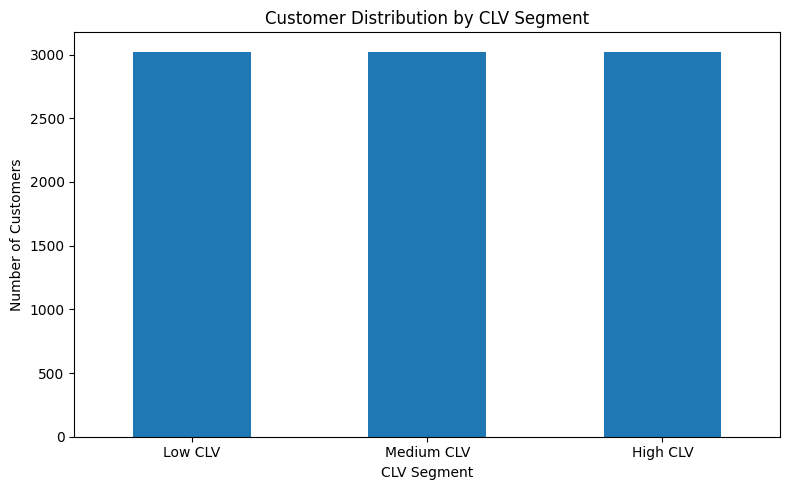

In [ ]:
###Grafik CLV Segment
plt.figure(figsize=(8, 5))

clv_count.plot(kind='bar')

plt.title('Customer Distribution by CLV Segment')
plt.xlabel('CLV Segment')
plt.ylabel('Number of Customers')

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
###Total CLV per Segment
clv_by_segment = (
    rfm_clv
    .groupby('CLV_Segment', observed=True)['CLV']
    .sum()
)

display(clv_by_segment)

,CLV
CLV_Segment,
Low CLV,14987692
Medium CLV,37435514
High CLV,70705396


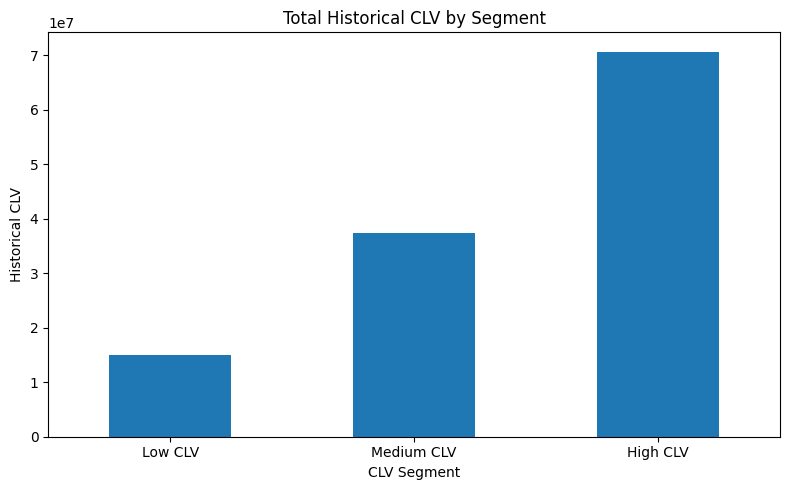

In [ ]:
plt.figure(figsize=(8, 5))

clv_by_segment.plot(kind='bar')

plt.title('Total Historical CLV by Segment')
plt.xlabel('CLV Segment')
plt.ylabel('Historical CLV')

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

**Hubungkan RFM dengan CLV**

Ini bagian yang sangat penting untuk assignment.

Kita ingin menjawab:

Apakah customer dengan RFM yang bagus juga mempunyai CLV tinggi?

In [ ]:
rfm_clv_summary = (
    rfm_clv
    .groupby('Segment')
    .agg(
        Customer_Count=('CustomerID', 'count'),
        Avg_Recency=('Recency', 'mean'),
        Avg_Frequency=('Frequency', 'mean'),
        Avg_Monetary=('Monetary', 'mean'),
        Total_CLV=('CLV', 'sum'),
        Avg_CLV=('CLV', 'mean')
    )
    .sort_values('Avg_CLV', ascending=False)
)

display(rfm_clv_summary)

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_CLV,Avg_CLV
Segment,,,,,,
Champions,891,46.572391,2.000000,47246.130191,18818802,21120.989899
At Risk,1298,227.707242,2.000000,40438.399076,24816842,19119.292758
Potential Loyalists,1059,48.355996,1.755430,37842.944287,18261578,17244.171860
Loyal Customers,940,95.861702,2.000000,34290.986170,15690127,16691.624468
Need Attention,2979,107.826116,1.624706,17000.566633,28517288,9572.772071
Lost Customers,1901,260.931089,1.072067,18269.839558,17023965,8955.268280


In [ ]:
####Cari Customer dengan CLV Tertinggi
top_clv = (
    rfm_clv
    .sort_values(
        'CLV',
        ascending=False
    )
    .head(10)
)

display(
    top_clv[
        [
            'CustomerID',
            'Recency',
            'Frequency',
            'Monetary',
            'Segment',
            'CLV',
            'CLV_Segment'
        ]
    ]
)

,CustomerID,Recency,Frequency,Monetary,Segment,CLV,CLV_Segment
2709,C1521,193,2,51400,At Risk,47900,High CLV
1221,C11181,196,2,82275,At Risk,47275,High CLV
2605,C1428,173,2,64585,At Risk,47085,High CLV
1030,C10993,21,2,61970,Potential Loyalists,45970,High CLV
8483,C9432,138,2,67800,Loyal Customers,45300,High CLV
4933,C3523,173,2,115090,At Risk,45090,High CLV
6038,C4518,121,2,95000,Loyal Customers,45000,High CLV
1943,C1188,188,2,60990,At Risk,44990,High CLV
3397,C2140,27,2,81683,Potential Loyalists,44683,High CLV
3022,C1803,51,2,66945,Potential Loyalists,44445,High CLV


In [ ]:
display(clv_count)

,count
CLV_Segment,
Low CLV,3023
Medium CLV,3022
High CLV,3023


In [ ]:
display(clv_by_segment)

,CLV
CLV_Segment,
Low CLV,14987692
Medium CLV,37435514
High CLV,70705396


In [ ]:
# Menggabungkan data RFM dengan data CLV
rfm_clv = rfm.merge(
    customer_value,
    on='CustomerID',
    how='left'
)

# Menambahkan segmentasi CLV
rfm_clv['CLV_Segment'] = pd.qcut(
    rfm_clv['CLV'].rank(method='first'),
    q=3,
    labels=['Low CLV', 'Medium CLV', 'High CLV']
)

# Cek hasil
display(rfm_clv.head())

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment,Total_Revenue,Total_Cost,Total_Profit,Total_Quantity,Transaction_Count,First_Purchase,Last_Purchase,Customer_Lifetime_Days,Average_Purchase_Value,CLV,CLV_Segment
0,C1,131,2,48212,3,2,5,325,Need Attention,48212,24000,24212,8,2,2024-09-24,2025-04-30,218,24106.0,24212,High CLV
1,C10,78,1,18280,4,1,2,412,Need Attention,18280,800,17480,4,1,2025-06-22,2025-06-22,0,18280.0,17480,High CLV
2,C100,202,2,15074,2,2,2,222,Lost Customers,15074,4000,11074,3,2,2025-01-10,2025-02-18,39,7537.0,11074,Medium CLV
3,C1000,308,2,22198,1,2,3,123,Lost Customers,22198,13000,9198,3,2,2024-09-23,2024-11-04,42,11099.0,9198,Medium CLV
4,C10000,56,2,25268,4,2,3,423,Potential Loyalists,25268,12200,13068,4,2,2025-06-26,2025-07-14,18,12634.0,13068,Medium CLV


In [ ]:
display(rfm_clv['CLV_Segment'].value_counts())

,count
CLV_Segment,
Low CLV,3023
High CLV,3023
Medium CLV,3022


In [ ]:
rfm_clv_summary = (
    rfm_clv
    .groupby(['Segment', 'CLV_Segment'], observed=True)
    .agg(
        Customer_Count=('CustomerID', 'count'),
        Total_CLV=('CLV', 'sum'),
        Average_CLV=('CLV', 'mean'),
        Average_Recency=('Recency', 'mean'),
        Average_Frequency=('Frequency', 'mean'),
        Average_Monetary=('Monetary', 'mean')
    )
    .reset_index()
)

display(rfm_clv_summary)

,Segment,CLV_Segment,Customer_Count,Total_CLV,Average_CLV,Average_Recency,Average_Frequency,Average_Monetary
0,At Risk,Low CLV,96,634459,6608.947917,227.562500,2.000000,29157.906250
1,At Risk,Medium CLV,421,5395403,12815.684086,230.895487,2.000000,34774.116390
2,At Risk,High CLV,781,18786980,24055.032010,226.006402,2.000000,44878.335467
3,Champions,Low CLV,37,247689,6694.297297,45.513514,2.000000,38667.270270
4,Champions,Medium CLV,241,3171873,13161.298755,46.755187,2.000000,41223.124481
5,Champions,High CLV,613,15399240,25121.109299,46.564437,2.000000,50131.876020
6,Lost Customers,Low CLV,1068,4604833,4311.641386,264.009363,1.026217,11418.195693
7,Lost Customers,Medium CLV,559,6733759,12046.080501,259.078712,1.094812,22726.223614
8,Lost Customers,High CLV,274,5685373,20749.536496,252.711679,1.204380,35884.572993
9,Loyal Customers,Low CLV,115,761830,6624.608696,89.295652,2.000000,27027.217391


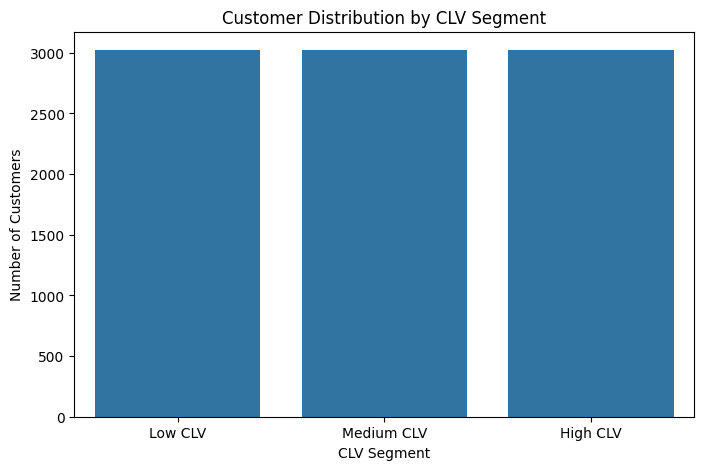

In [ ]:
#####Jumlah customer berdasarkan CLV
plt.figure(figsize=(8,5))

sns.countplot(
    data=rfm_clv,
    x='CLV_Segment',
    order=['Low CLV', 'Medium CLV', 'High CLV']
)

plt.title('Customer Distribution by CLV Segment')
plt.xlabel('CLV Segment')
plt.ylabel('Number of Customers')
plt.show()

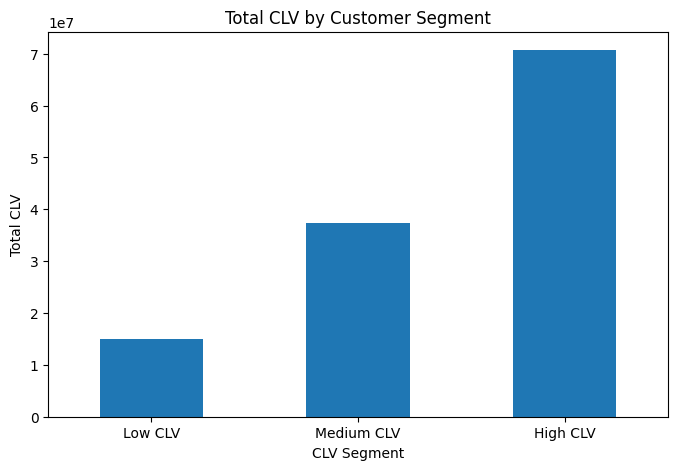

In [ ]:
###Total CLV berdasarkan segment
clv_plot = (
    rfm_clv
    .groupby('CLV_Segment', observed=True)['CLV']
    .sum()
    .reindex(['Low CLV', 'Medium CLV', 'High CLV'])
)

plt.figure(figsize=(8,5))

clv_plot.plot(kind='bar')

plt.title('Total CLV by Customer Segment')
plt.xlabel('CLV Segment')
plt.ylabel('Total CLV')
plt.xticks(rotation=0)
plt.show()

In [ ]:

###Buat table gabungan RFM + CLV
rfm_clv_summary = (
    rfm_clv
    .groupby(['Segment', 'CLV_Segment'], observed=True)
    .agg(
        Customer_Count=('CustomerID', 'count'),
        Total_CLV=('CLV', 'sum'),
        Average_CLV=('CLV', 'mean'),
        Average_Recency=('Recency', 'mean'),
        Average_Frequency=('Frequency', 'mean'),
        Average_Monetary=('Monetary', 'mean')
    )
    .reset_index()
)

display(rfm_clv_summary)

,Segment,CLV_Segment,Customer_Count,Total_CLV,Average_CLV,Average_Recency,Average_Frequency,Average_Monetary
0,At Risk,Low CLV,96,634459,6608.947917,227.562500,2.000000,29157.906250
1,At Risk,Medium CLV,421,5395403,12815.684086,230.895487,2.000000,34774.116390
2,At Risk,High CLV,781,18786980,24055.032010,226.006402,2.000000,44878.335467
3,Champions,Low CLV,37,247689,6694.297297,45.513514,2.000000,38667.270270
4,Champions,Medium CLV,241,3171873,13161.298755,46.755187,2.000000,41223.124481
5,Champions,High CLV,613,15399240,25121.109299,46.564437,2.000000,50131.876020
6,Lost Customers,Low CLV,1068,4604833,4311.641386,264.009363,1.026217,11418.195693
7,Lost Customers,Medium CLV,559,6733759,12046.080501,259.078712,1.094812,22726.223614
8,Lost Customers,High CLV,274,5685373,20749.536496,252.711679,1.204380,35884.572993
9,Loyal Customers,Low CLV,115,761830,6624.608696,89.295652,2.000000,27027.217391


In [ ]:
rfm_clv_summary['Total_CLV'] = rfm_clv_summary['Total_CLV'].round(0)
rfm_clv_summary['Average_CLV'] = rfm_clv_summary['Average_CLV'].round(0)

display(rfm_clv_summary)

,Segment,CLV_Segment,Customer_Count,Total_CLV,Average_CLV,Average_Recency,Average_Frequency,Average_Monetary
0,At Risk,Low CLV,96,634459,6609.0,227.562500,2.000000,29157.906250
1,At Risk,Medium CLV,421,5395403,12816.0,230.895487,2.000000,34774.116390
2,At Risk,High CLV,781,18786980,24055.0,226.006402,2.000000,44878.335467
3,Champions,Low CLV,37,247689,6694.0,45.513514,2.000000,38667.270270
4,Champions,Medium CLV,241,3171873,13161.0,46.755187,2.000000,41223.124481
5,Champions,High CLV,613,15399240,25121.0,46.564437,2.000000,50131.876020
6,Lost Customers,Low CLV,1068,4604833,4312.0,264.009363,1.026217,11418.195693
7,Lost Customers,Medium CLV,559,6733759,12046.0,259.078712,1.094812,22726.223614
8,Lost Customers,High CLV,274,5685373,20750.0,252.711679,1.204380,35884.572993
9,Loyal Customers,Low CLV,115,761830,6625.0,89.295652,2.000000,27027.217391


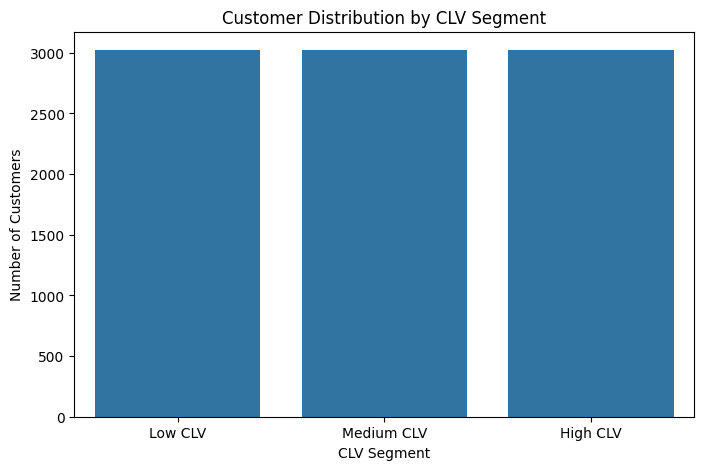

In [ ]:
####Buat visualisasi CLV
plt.figure(figsize=(8,5))

sns.countplot(
    data=rfm_clv,
    x='CLV_Segment',
    order=['Low CLV', 'Medium CLV', 'High CLV']
)

plt.title('Customer Distribution by CLV Segment')
plt.xlabel('CLV Segment')
plt.ylabel('Number of Customers')
plt.show()

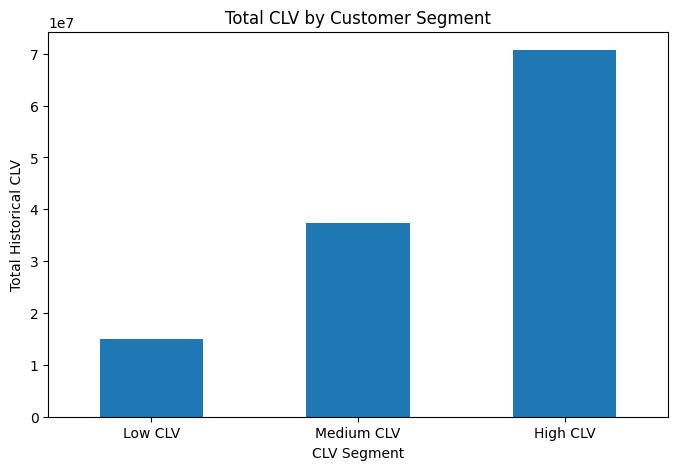

In [ ]:
clv_plot = (
    rfm_clv
    .groupby('CLV_Segment', observed=True)['CLV']
    .sum()
    .reindex(['Low CLV', 'Medium CLV', 'High CLV'])
)

plt.figure(figsize=(8,5))

clv_plot.plot(kind='bar')

plt.title('Total CLV by Customer Segment')
plt.xlabel('CLV Segment')
plt.ylabel('Total Historical CLV')
plt.xticks(rotation=0)
plt.show()

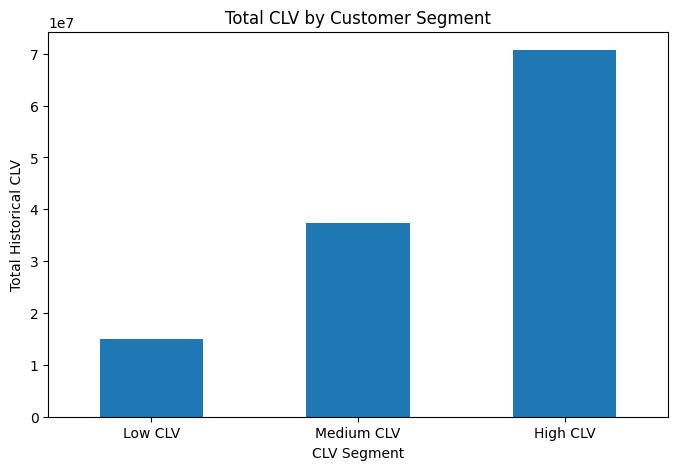

In [ ]:
####Total CLV
clv_plot = (
    rfm_clv
    .groupby('CLV_Segment', observed=True)['CLV']
    .sum()
    .reindex(['Low CLV', 'Medium CLV', 'High CLV'])
)

plt.figure(figsize=(8,5))

clv_plot.plot(kind='bar')

plt.title('Total CLV by Customer Segment')
plt.xlabel('CLV Segment')
plt.ylabel('Total Historical CLV')
plt.xticks(rotation=0)
plt.show()

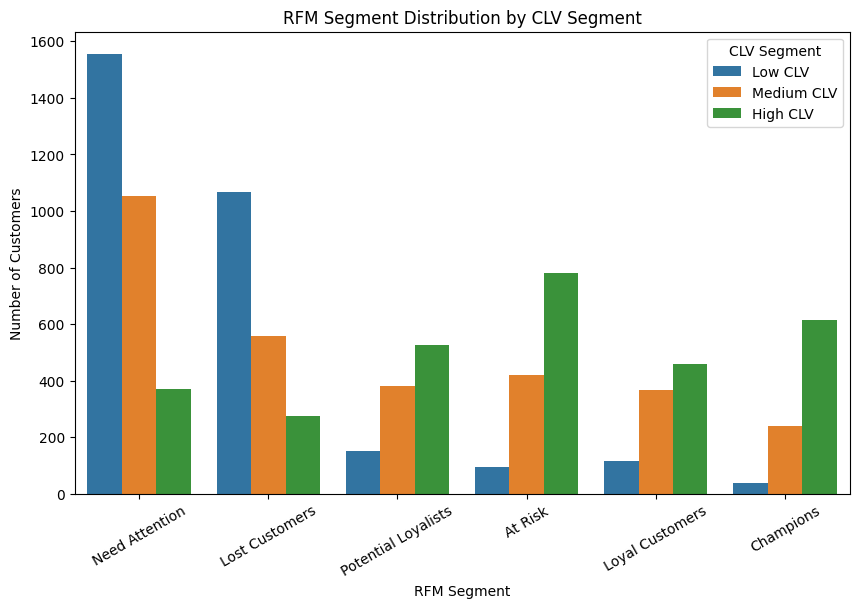

In [ ]:
#####Visualisasi RFM vs CLV
plt.figure(figsize=(10,6))

sns.countplot(
    data=rfm_clv,
    x='Segment',
    hue='CLV_Segment'
)

plt.title('RFM Segment Distribution by CLV Segment')
plt.xlabel('RFM Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=30)
plt.legend(title='CLV Segment')
plt.show()

In [ ]:
#### Cari customer dengan nilai CLV tertinggi
top_clv_customers = (
    rfm_clv[
        ['CustomerID',
         'CLV',
         'CLV_Segment',
         'Segment',
         'Recency',
         'Frequency',
         'Monetary']
    ]
    .sort_values('CLV', ascending=False)
    .head(10)
)

display(top_clv_customers)

,CustomerID,CLV,CLV_Segment,Segment,Recency,Frequency,Monetary
2709,C1521,47900,High CLV,At Risk,193,2,51400
1221,C11181,47275,High CLV,At Risk,196,2,82275
2605,C1428,47085,High CLV,At Risk,173,2,64585
1030,C10993,45970,High CLV,Potential Loyalists,21,2,61970
8483,C9432,45300,High CLV,Loyal Customers,138,2,67800
4933,C3523,45090,High CLV,At Risk,173,2,115090
6038,C4518,45000,High CLV,Loyal Customers,121,2,95000
1943,C1188,44990,High CLV,At Risk,188,2,60990
3397,C2140,44683,High CLV,Potential Loyalists,27,2,81683
3022,C1803,44445,High CLV,Potential Loyalists,51,2,66945


In [ ]:
#######Cari customer yang berisiko tetapi bernilai tinggi
high_value_at_risk = rfm_clv[
    (rfm_clv['CLV_Segment'] == 'High CLV') &
    (rfm_clv['Segment'] == 'At Risk')
].sort_values('CLV', ascending=False)

display(high_value_at_risk.head(10))

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment,Total_Revenue,Total_Cost,Total_Profit,Total_Quantity,Transaction_Count,First_Purchase,Last_Purchase,Customer_Lifetime_Days,Average_Purchase_Value,CLV,CLV_Segment
2709,C1521,193,2,51400,2,3,5,235,At Risk,51400,3500,47900,10,2,2024-12-07,2025-02-27,82,25700.0,47900,High CLV
1221,C11181,196,2,82275,2,3,5,235,At Risk,82275,35000,47275,10,2,2024-12-25,2025-02-24,61,41137.5,47275,High CLV
2605,C1428,173,2,64585,2,3,5,235,At Risk,64585,17500,47085,10,2,2024-10-25,2025-03-19,145,32292.5,47085,High CLV
4933,C3523,173,2,115090,2,4,5,245,At Risk,115090,70000,45090,10,2,2024-12-17,2025-03-19,92,57545.0,45090,High CLV
1943,C1188,188,2,60990,2,3,5,235,At Risk,60990,16000,44990,10,2,2024-12-11,2025-03-04,83,30495.0,44990,High CLV
5940,C443,315,2,85916,1,4,5,145,At Risk,85916,43000,42916,9,2,2024-09-14,2024-10-28,44,42958.0,42916,High CLV
8223,C9179,183,2,43890,2,5,5,255,At Risk,43890,1800,42090,9,2,2025-02-26,2025-03-09,11,21945.0,42090,High CLV
7654,C5973,183,2,84496,2,5,5,255,At Risk,84496,43000,41496,9,2,2024-10-17,2025-03-09,143,42248.0,41496,High CLV
1594,C11542,188,2,76590,2,3,5,235,At Risk,76590,36000,40590,9,2,2024-12-10,2025-03-04,84,38295.0,40590,High CLV
8879,C9817,238,2,76585,1,5,5,155,At Risk,76585,36000,40585,10,2,2024-12-01,2025-01-13,43,38292.5,40585,High CLV


In [ ]:
#####Cari Champions dengan High CLV
champions_high_clv = rfm_clv[
    (rfm_clv['Segment'] == 'Champions') &
    (rfm_clv['CLV_Segment'] == 'High CLV')
]

print("Jumlah Champions + High CLV:",
      len(champions_high_clv))

display(
    champions_high_clv[
        ['CustomerID', 'Recency', 'Frequency', 'Monetary', 'CLV']
    ].sort_values('CLV', ascending=False).head(10)
)

Jumlah Champions + High CLV: 613


,CustomerID,Recency,Frequency,Monetary,CLV
4818,C342,38,2,63883,43083
5512,C4044,19,2,89794,42794
8230,C9185,18,2,72445,42445
6185,C4650,64,2,77740,41740
4562,C319,32,2,77735,41735
8428,C9381,24,2,75995,40995
4328,C298,93,2,78165,40665
8317,C9269,15,2,43660,40160
5449,C3989,48,2,41975,39975
8397,C935,57,2,94800,39800


In [ ]:
####Buat matriks strategi
def strategy_group(row):

    if row['Segment'] == 'Champions' and row['CLV_Segment'] == 'High CLV':
        return 'VIP / Retain'

    elif row['Segment'] == 'At Risk' and row['CLV_Segment'] == 'High CLV':
        return 'Win Back'

    elif row['Segment'] == 'Loyal Customers' and row['CLV_Segment'] in ['Medium CLV', 'High CLV']:
        return 'Upsell / Cross-sell'

    elif row['Segment'] == 'Potential Loyalists':
        return 'Develop'

    elif row['Segment'] == 'Lost Customers':
        return 'Reactivate'

    else:
        return 'Monitor'


rfm_clv['Strategy_Group'] = rfm_clv.apply(
    strategy_group,
    axis=1
)

display(
    rfm_clv['Strategy_Group'].value_counts()
)

,count
Strategy_Group,
Monitor,3889
Reactivate,1901
Develop,1059
Upsell / Cross-sell,825
Win Back,781
VIP / Retain,613


In [ ]:
####Buat table strategi
strategy_summary = (
    rfm_clv
    .groupby('Strategy_Group')
    .agg(
        Customer_Count=('CustomerID', 'count'),
        Total_CLV=('CLV', 'sum'),
        Average_CLV=('CLV', 'mean'),
        Average_Frequency=('Frequency', 'mean'),
        Average_Monetary=('Monetary', 'mean')
    )
    .reset_index()
    .sort_values('Total_CLV', ascending=False)
)

display(strategy_summary)

,Strategy_Group,Customer_Count,Total_CLV,Average_CLV,Average_Frequency,Average_Monetary
1,Monitor,3889,38728542,9958.483415,1.712522,21228.424274
5,Win Back,781,18786980,24055.032010,2.000000,44878.335467
0,Develop,1059,18261578,17244.171860,1.755430,37842.944287
2,Reactivate,1901,17023965,8955.268280,1.072067,18269.839558
4,VIP / Retain,613,15399240,25121.109299,2.000000,50131.876020
3,Upsell / Cross-sell,825,14928297,18094.905455,2.000000,35303.511515


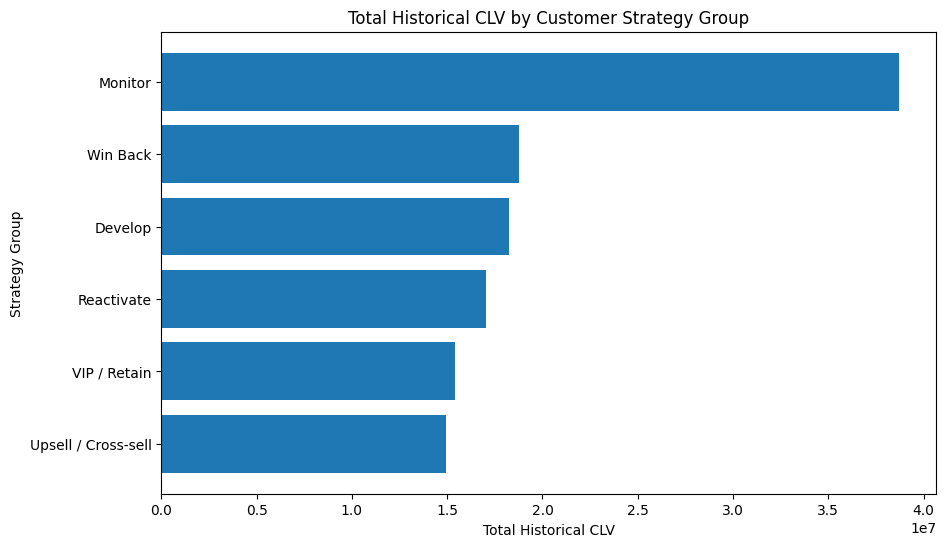

In [ ]:
####Buat visualisasi strategi
plt.figure(figsize=(10,6))

strategy_plot = (
    strategy_summary
    .sort_values('Total_CLV', ascending=True)
)

plt.barh(
    strategy_plot['Strategy_Group'],
    strategy_plot['Total_CLV']
)

plt.title('Total Historical CLV by Customer Strategy Group')
plt.xlabel('Total Historical CLV')
plt.ylabel('Strategy Group')

plt.show()

In [ ]:
####Cek kontribusi CLV

###Sekarang kita hitung persentase kontribusi setiap segment.

clv_contribution = (
    rfm_clv
    .groupby('CLV_Segment', observed=True)['CLV']
    .sum()
    .reset_index()
)

total_clv = clv_contribution['CLV'].sum()

clv_contribution['CLV_Contribution_%'] = (
    clv_contribution['CLV'] / total_clv * 100
)

display(clv_contribution)

,CLV_Segment,CLV,CLV_Contribution_%
0,Low CLV,14987692,12.172389
1,Medium CLV,37435514,30.403589
2,High CLV,70705396,57.424022


**BUSINESS INSIGHT**

In [ ]:
print("===== OVERALL KPI =====")

print("Total Customer:",
      rfm_clv['CustomerID'].nunique())

print("Total Transaction:",
      len(df_clean))

print("Total Revenue:",
      df_clean['SalesAmount'].sum())

print("Total Profit:",
      df_clean['Profit'].sum())

print("Average Transaction:",
      df_clean['SalesAmount'].mean())

===== OVERALL KPI =====
Total Customer: 9068
Total Transaction: 14995
Total Revenue: 252270202
Total Profit: 123128602
Average Transaction: 16823.621340446814


In [ ]:
print("\n===== RFM SEGMENT =====")

display(
    rfm['Segment']
    .value_counts()
)


===== RFM SEGMENT =====


,count
Segment,
Need Attention,2979
Lost Customers,1901
At Risk,1298
Potential Loyalists,1059
Loyal Customers,940
Champions,891


In [ ]:
print("\n===== CLV SEGMENT =====")

display(
    rfm_clv['CLV_Segment']
    .value_counts()
)


===== CLV SEGMENT =====


,count
CLV_Segment,
Low CLV,3023
High CLV,3023
Medium CLV,3022


In [ ]:
rfm_clv_matrix = pd.crosstab(
    rfm_clv['Segment'],
    rfm_clv['CLV_Segment']
)

display(rfm_clv_matrix)

CLV_Segment,Low CLV,Medium CLV,High CLV
Segment,,,
At Risk,96,421,781
Champions,37,241,613
Lost Customers,1068,559,274
Loyal Customers,115,367,458
Need Attention,1556,1052,371
Potential Loyalists,151,382,526


In [ ]:
rfm_clv_matrix_value = (
    rfm_clv
    .groupby(
        ['Segment', 'CLV_Segment'],
        observed=True
    )['CLV']
    .agg(['count', 'sum', 'mean'])
    .reset_index()
)

display(rfm_clv_matrix_value)

,Segment,CLV_Segment,count,sum,mean
0,At Risk,Low CLV,96,634459,6608.947917
1,At Risk,Medium CLV,421,5395403,12815.684086
2,At Risk,High CLV,781,18786980,24055.032010
3,Champions,Low CLV,37,247689,6694.297297
4,Champions,Medium CLV,241,3171873,13161.298755
5,Champions,High CLV,613,15399240,25121.109299
6,Lost Customers,Low CLV,1068,4604833,4311.641386
7,Lost Customers,Medium CLV,559,6733759,12046.080501
8,Lost Customers,High CLV,274,5685373,20749.536496
9,Loyal Customers,Low CLV,115,761830,6624.608696


In [ ]:
df.isnull().sum()
df.duplicated().sum()
df.describe()

,Date,Years,Quantity,SalesAmount,Cost,Customer_Master.Age,Profit
count,14999,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,2025-03-10 00:45:24.661644288,2024.689446,2.978665,16819.842389,8612.427495,41.286352,8207.414894
min,2024-02-28 00:00:00,2024.000000,-3.000000,0.000000,0.000000,18.000000,-35000.000000
25%,2024-12-08 00:00:00,2024.000000,2.000000,7390.000000,1000.000000,29.000000,3507.500000
50%,2025-03-11 00:00:00,2025.000000,3.000000,13833.000000,6000.000000,41.000000,6780.000000
75%,2025-06-09 00:00:00,2025.000000,4.000000,23419.000000,14000.000000,53.000000,11910.000000
max,2025-09-07 00:00:00,2025.000000,5.000000,59970.000000,35000.000000,65.000000,24995.000000
std,NaN,0.462736,1.407341,12167.277846,9133.940374,13.906742,5817.419938


In [ ]:
df['Profit'] = df['SalesAmount'] - df['Cost']

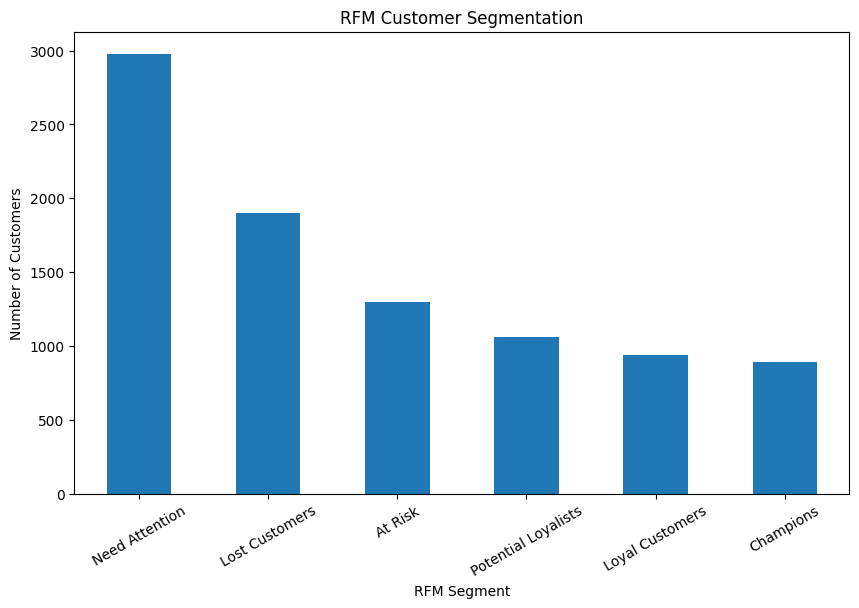

In [ ]:
plt.figure(figsize=(10,6))

rfm['Segment'].value_counts().plot(kind='bar')

plt.title('RFM Customer Segmentation')
plt.xlabel('RFM Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=30)
plt.show()

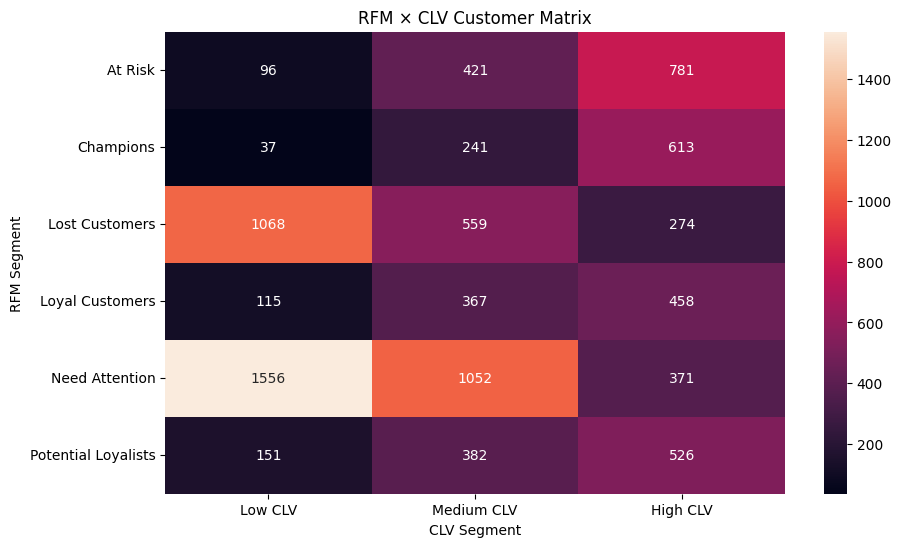

In [ ]:
plt.figure(figsize=(10,6))

sns.heatmap(
    rfm_clv_matrix,
    annot=True,
    fmt='d'
)

plt.title('RFM × CLV Customer Matrix')
plt.xlabel('CLV Segment')
plt.ylabel('RFM Segment')
plt.show()